In [ ]:
#KNN KNeighborsClassifier
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [ ]:
# dataset
data = np.array([[25, 30, 1], [20, 31, 2], [22, 29, 1], [24, 28, 1],[18, 27, 2],[26, 32, 1]])
labels = np.array([1, 0, 1, 0, 2, 1]) #0:low, 1:medium, 2:high


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)


In [ ]:
#step 3
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
# step 4
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)


In [ ]:
accuracy = knn.score(X_test, y_test)
print(f"Model accuracy: {accuracy * 100:.2f}%")

In [ ]:
#user input
user_data = np.array([[23, 30, 2]])
user_data = scaler.transform(user_data)
prediction = knn.predict(user_data)
print(f"Predicted marketing strategy: {prediction[0]}")

<p style="color:yellow;">Data Analysis Project Example: အမျိုးသားဥယျာဉ်များ ဧည့်သည်လာရောက်မှု ဆန်းစစ်ခြင်း</p>

<p style="color:blue;">အမေရိကန်အမျိုးသားဥယျာဉ်များ၏ ဧည့်သည်လာရောက်မှုအပေါ် လွှမ်းမိုးမှုရှိသော အကြောင်းရင်းများကို နားလည်ရန်၊ ရာသီအလိုက် လာရောက်မှုပုံစံများကို ခန့်မှန်းရန် နှင့် ဥယျာဉ်အမျိုးအစားအလိုက် ကွဲပြားမှုများကို ဆန်းစစ်ရန်။

</p>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ဒေတာဖတ်ခြင်း
np_data = pd.read_csv('national_parks_visitation.csv')

In [3]:
# ဒေတာအချက်အလက်များ စစ်ဆေးခြင်း
print(np_data.info())
print(np_data.isnull().sum())

# ပျောက်ဆုံးနေသော အချက်အလက်များကို ဖြေရှင်းခြင်း
np_data = np_data.dropna()  # သို့မဟုတ်
np_data['visitors'].fillna(np_data['visitors'].median(), inplace=True)

# ဒေတာအမျိုးအစားပြောင်းလဲခြင်း
np_data['date'] = pd.to_datetime(np_data['date'])
np_data['year'] = np_data['date'].dt.year
np_data['month'] = np_data['date'].dt.month

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   park_code                    48 non-null     object        
 1   park_name                    48 non-null     object        
 2   park_type                    48 non-null     object        
 3   state                        48 non-null     object        
 4   date                         48 non-null     datetime64[ns]
 5   visitors                     48 non-null     int64         
 6   area_sq_miles                48 non-null     float64       
 7   annual_precipitation_inches  48 non-null     float64       
 8   elevation_ft                 48 non-null     int64         
 9   year                         48 non-null     int32         
 10  month                        48 non-null     int32         
dtypes: datetime64[ns](1), float64(2), int32(2), int

C:\Users\E15\AppData\Local\Temp\ipykernel_9016\1270057644.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  np_data['visitors'].fillna(np_data['visitors'].median(), inplace=True)


                      date      visitors  area_sq_miles  \
count                   48  4.800000e+01      48.000000   
mean   2010-06-16 12:00:00  4.380229e+05    1046.981500   
min    2010-01-01 00:00:00  9.800000e+03      47.400000   
25%    2010-03-24 06:00:00  6.720000e+04     121.800000   
50%    2010-06-16 00:00:00  2.071500e+05     334.513000   
75%    2010-09-08 12:00:00  6.829750e+05    1259.694500   
max    2010-12-01 00:00:00  1.689000e+06    3471.500000   
std                    NaN  4.778451e+05    1425.897115   

       annual_precipitation_inches  elevation_ft    year      month  
count                     48.00000     48.000000    48.0  48.000000  
mean                      38.47500   5632.500000  2010.0   6.500000  
min                       15.90000   1530.000000  2010.0   1.000000  
25%                       19.35000   5257.500000  2010.0   3.750000  
50%                       38.15000   6500.000000  2010.0   6.500000  
75%                       57.27500   6875.000000

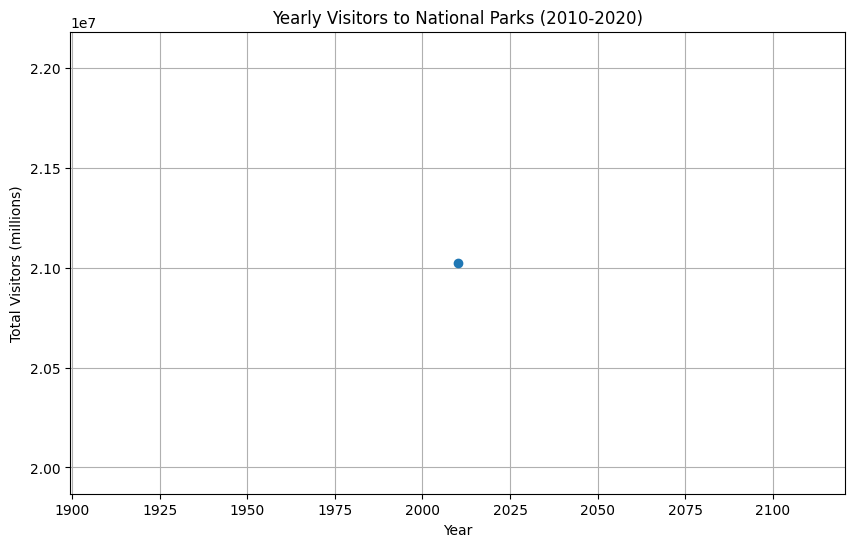

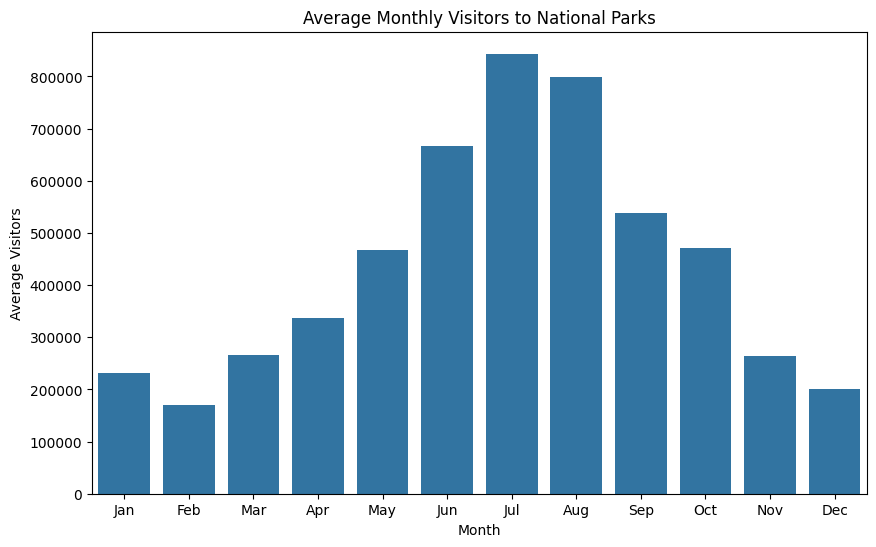

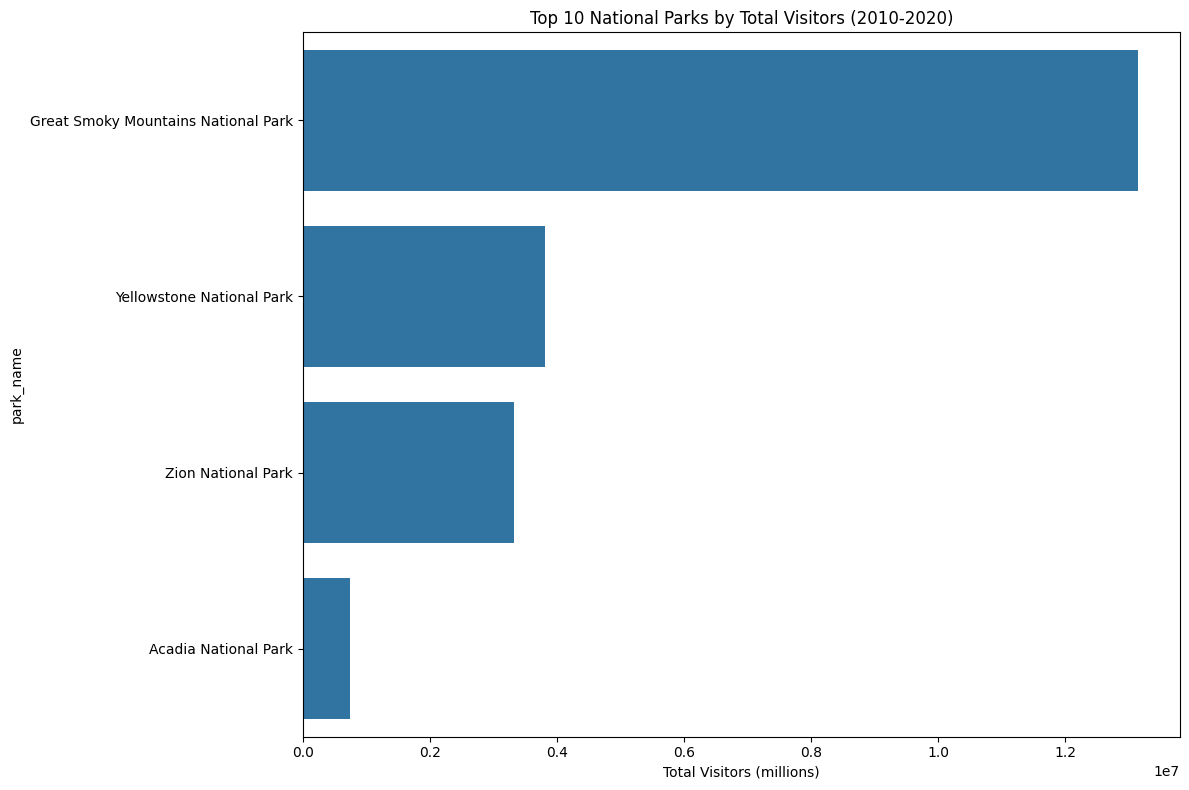

In [4]:
# စာရင်းဇယားဆိုင်ရာ အချက်အလက်များ
print(np_data.describe())

# နှစ်အလိုက် စုစုပေါင်းဧည့်သည်များ
yearly_visitors = np_data.groupby('year')['visitors'].sum()
plt.figure(figsize=(10, 6))
plt.plot(yearly_visitors.index, yearly_visitors.values, marker='o')
plt.title('Yearly Visitors to National Parks (2010-2020)')
plt.xlabel('Year')
plt.ylabel('Total Visitors (millions)')
plt.grid(True)
plt.show()

# လအလိုက် ပျမ်းမျှဧည့်သည်များ
monthly_avg = np_data.groupby('month')['visitors'].mean()
plt.figure(figsize=(10, 6))
sns.barplot(x=monthly_avg.index, y=monthly_avg.values)
plt.title('Average Monthly Visitors to National Parks')
plt.xlabel('Month')
plt.ylabel('Average Visitors')
plt.xticks(ticks=range(0,12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

# အမျိုးသားဥယျာဉ်အလိုက် ဧည့်သည်အများဆုံး ၁၀ ခု
top_parks = np_data.groupby('park_name')['visitors'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(12, 8))
sns.barplot(y=top_parks.index, x=top_parks.values)
plt.title('Top 10 National Parks by Total Visitors (2010-2020)')
plt.xlabel('Total Visitors (millions)')
plt.tight_layout()
plt.show()

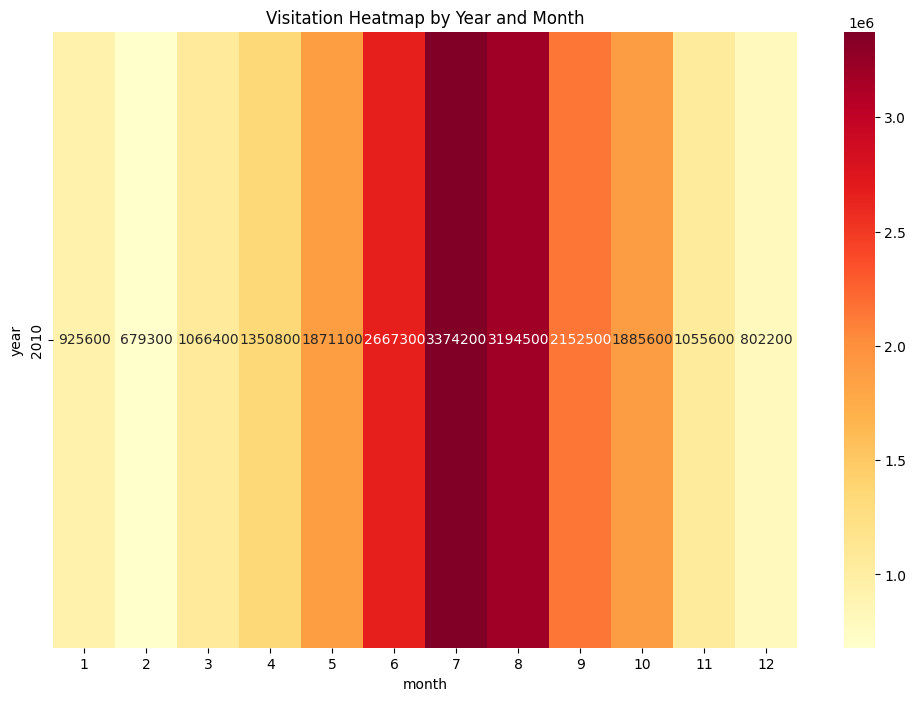

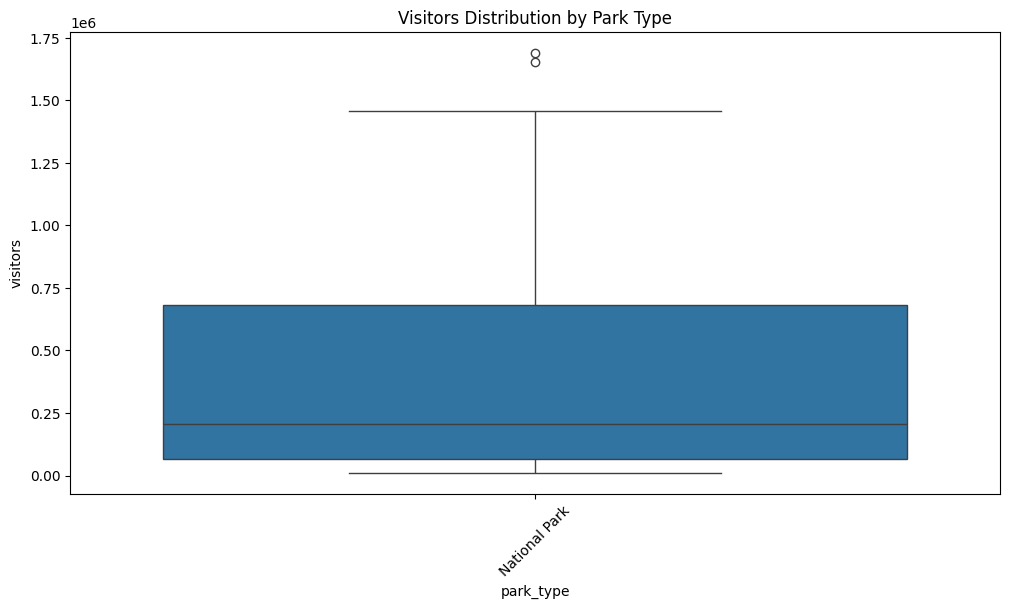

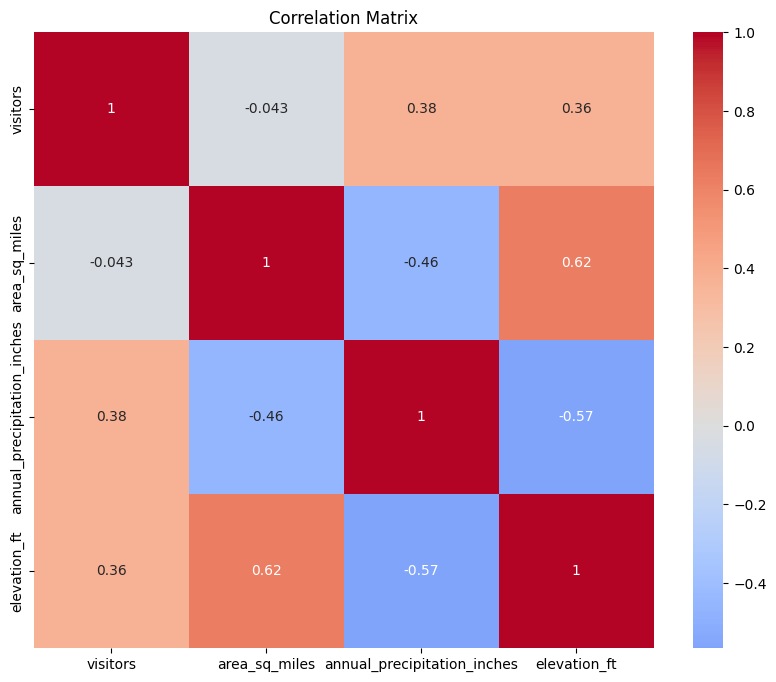

In [5]:
# Heatmap - လနှင့်နှစ်အလိုက် ဧည့်သည်လာရောက်မှု
pivot_table = np_data.pivot_table(values='visitors', index='year', columns='month', aggfunc='sum')
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, cmap='YlOrRd', annot=True, fmt='.0f')
plt.title('Visitation Heatmap by Year and Month')
plt.show()

# Box plot - ဥယျာဉ်အမျိုးအစားအလိုက် ဧည့်သည်လာရောက်မှု
plt.figure(figsize=(12, 6))
sns.boxplot(x='park_type', y='visitors', data=np_data)
plt.title('Visitors Distribution by Park Type')
plt.xticks(rotation=45)
plt.show()

# Correlation matrix
numeric_cols = ['visitors', 'area_sq_miles', 'annual_precipitation_inches', 'elevation_ft']
correlation_matrix = np_data[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

Mean Squared Error: 56323462123.43
R-squared Score: 0.65


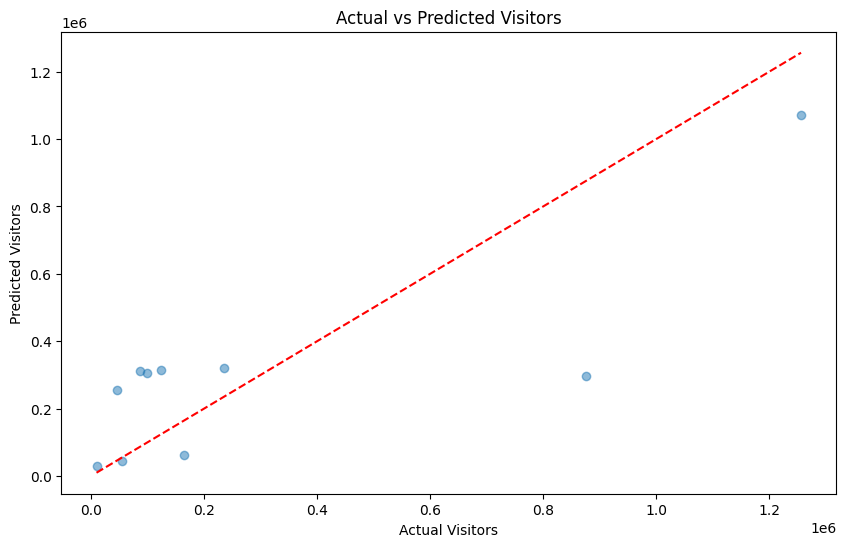

In [6]:
# Features နှင့် target variable ခွဲခြားခြင်း
features = ['month', 'area_sq_miles', 'annual_precipitation_inches', 'elevation_ft']
X = np_data[features]
y = np_data['visitors']

# Training နှင့် testing sets ခွဲခြားခြင်း
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression မော်ဒယ်တည်ဆောက်ခြင်း
model = LinearRegression()
model.fit(X_train, y_train)

# ခန့်မှန်းခြင်း
y_pred = model.predict(X_test)

# မော်ဒယ်စွမ်းဆောင်ရည် အကဲဖြတ်ခြင်း
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared Score: {r2:.2f}')

# Actual vs Predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Visitors')
plt.ylabel('Predicted Visitors')
plt.title('Actual vs Predicted Visitors')
plt.show()